# Palette automatique de couleurs : implémentation et analyse de la méthode ACoPa

**Projet 4IM01 – Télécom Paris, filière Imagerie – binôme : Aziz et Hugo**

Article étudié : J. Delon, A. Desolneux, J.-L. Lisani, A.-B. Petro, *Automatic Color Palette*, Inverse Problems and Imaging 1(2), 2007, p. 265-287.

Ce notebook nous sert de rapport. On y présente les méthodes que nous avons implémentées, le code qui produit toutes les figures, nos expériences, notre analyse critique, et la façon dont nous avons utilisé les agents conversationnels. Le code des méthodes est dans les fichiers `.py` du dépôt. Le `README.md` précise qui a écrit chaque fichier.

**Plan**
1. Le problème : réduire une image à quelques couleurs
2. Les méthodes classiques, par lesquelles nous avons commencé
3. La méthode ACoPa : histogrammes, test d'unimodalité, algorithme FTC
4. Expériences
5. Analyse critique
6. Utilisation des agents conversationnels
7. Répartition du travail et références

## 1. Le problème

Une image couleur 8 bits peut contenir jusqu'à $256^3 \approx 16{,}7$ millions de couleurs. `Poivrons.jpeg` ($512\times512$) en contient environ 87 000. On cherche une **palette** : un petit ensemble de $K$ couleurs qui suffit à représenter l'image, chaque pixel étant remplacé par la couleur de la palette la plus proche. Ça sert à la compression, à l'affichage avec peu de couleurs, à la description d'une image (« rouge, vert, jaune ») ou au rendu « cartoon ».

En travaillant sur le sujet, deux questions nous sont vite apparues :
- **combien** de couleurs garder ($K$) ;
- **lesquelles** garder, surtout quand une couleur vive n'occupe qu'une petite zone de l'image.

Les méthodes classiques demandent $K$ à l'utilisateur et cherchent surtout à minimiser une erreur moyenne. L'article propose une méthode, **ACoPa**, qui trouve $K$ toute seule et garde les petites zones de couleur, grâce à une analyse statistique des histogrammes de teinte, de saturation et d'intensité. C'est cette méthode que nous avons cherché à reproduire.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from skimage.color import rgb2lab, deltaE_cie76

import median_cut, popularite, kmeans_rapide
import segmentation_naive as naive
import segmentation_auto as auto
import complements

plt.rcParams["figure.dpi"] = 80


def charger(chemin):
    return np.array(Image.open(chemin).convert("RGB"))


def mesures(image, quantifiee, masque=None):
    # MSE et PSNR calculés sur RGB, et écart de couleur dE (CIE76) dans l'espace Lab,
    # qui est plus proche de ce que voit l'oeil. dE < 2-3 : différence à peine visible.
    mse = ((image.astype(float) - quantifiee.astype(float)) ** 2).mean()
    psnr = 10 * np.log10(255 ** 2 / mse)
    dE = deltaE_cie76(rgb2lab(image / 255), rgb2lab(quantifiee / 255))
    ligne = [mse, psnr, dE.mean()]
    if masque is not None:
        ligne.append(dE[masque].mean())  # erreur sur une petite zone de couleur choisie
    return ligne


def methodes_classiques(image, K):
    resultats = {}
    resultats["Popularité"] = popularite.remplacer_par_palette(image, popularite.popularite(image, K))
    resultats["Median cut"] = median_cut.remap(image, median_cut.median_cut(image, K))
    centres, labels = kmeans_rapide.kmeans(image, kmeans_rapide.centres_aleatoires(image, K), afficher=False)
    resultats["K-means (hasard)"] = kmeans_rapide.image_depuis_labels(centres, labels)
    return resultats


def ajouter_mean_shift(resultats, image, K):
    # Mean-Shift réglé pour donner environ K couleurs (voir complements.py)
    for espace in ["RGB", "Lab"]:
        finale, palette = complements.mean_shift(image, K, espace)
        resultats[f"Mean-Shift {espace} (K={len(palette)})"] = finale


def afficher_tableau(image, resultats, masque=None):
    entete = f"{'Méthode':26s}{'MSE':>9s}{'PSNR (dB)':>11s}{'dE moyen':>10s}"
    if masque is not None:
        entete += f"{'dE petite zone':>16s}"
    print(entete)
    for nom, q in resultats.items():
        valeurs = mesures(image, q, masque)
        ligne = f"{nom:26s}{valeurs[0]:9.1f}{valeurs[1]:11.2f}{valeurs[2]:10.2f}"
        if masque is not None:
            ligne += f"{valeurs[3]:16.2f}"
        print(ligne)


def afficher_grille(images, titres, ncol=3, taille=3.3):
    nlig = int(np.ceil(len(images) / ncol))
    fig, axes = plt.subplots(nlig, ncol, figsize=(taille * ncol, taille * nlig))
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, im, t in zip(np.ravel(axes), images, titres):
        ax.imshow(im)
        ax.set_title(t, fontsize=9)
    plt.tight_layout()
    plt.show()


poivrons = charger("images/Poivrons.jpeg")
fleur = charger("images/fleur.tif")
for nom, im in [("Poivrons", poivrons), ("Fleur", fleur)]:
    print(f"{nom} : {im.shape[1]}x{im.shape[0]} pixels, {len(np.unique(im.reshape(-1, 3), axis=0))} couleurs distinctes")

Poivrons : 512x512 pixels, 86757 couleurs distinctes


Fleur : 604x562 pixels, 157458 couleurs distinctes


## 2. Les méthodes classiques, par lesquelles nous avons commencé

On a commencé le projet par ces méthodes, pour prendre en main le problème et voir concrètement leurs limites. Nos premiers essais de K-means « à la main », avec une double boucle sur les pixels, sont gardés dans `apprentissage/`. Ils prenaient plusieurs minutes par image, ce qui nous a poussés à écrire ensuite une version vectorisée avec NumPy (`kmeans_rapide.py`).

**Popularité.** On regroupe les couleurs proches dans des cases, en gardant les 4 bits de poids fort de chaque canal (soit $16^3$ cases). On garde ensuite les $K$ cases qui contiennent le plus de pixels. *Exemple :* sur les poivrons, les cases rouges et vertes sont très remplies et sont gardées, mais une petite zone jaune n'est jamais parmi les $K$ plus remplies.

**Median cut** (Heckbert, 1982). On part d'une boîte qui contient tous les pixels dans le cube RGB. On coupe en deux, à la médiane, la boîte choisie, selon l'axe où elle est la plus étendue, et on recommence jusqu'à avoir $K$ boîtes. La couleur de chaque boîte est la moyenne de ses pixels. *Exemple :* pour $K=2$, la première coupe sépare souvent les pixels sombres des pixels clairs, car c'est la direction où le nuage de points est le plus étalé.

**K-means.** On cherche $K$ centres $c_1,\dots,c_K$ qui minimisent $\sum_{p}\min_k \lVert x_p - c_k\rVert^2$. On alterne deux étapes : chaque pixel va vers son centre le plus proche, puis chaque centre devient la moyenne de ses pixels. Le résultat dépend des centres de départ. *Exemple :* lors de nos premiers essais, on avait pris comme centres des couleurs « pures » (rouge, vert, bleu…) qui n'existent pas dans l'image, et on obtenait une image presque entièrement marron.

Ces essais nous ont fait comprendre deux défauts communs : **$K$ est fixé à la main**, et ces méthodes favorisent les couleurs **fréquentes**, puisque le critère est une erreur moyenne sur tous les pixels.

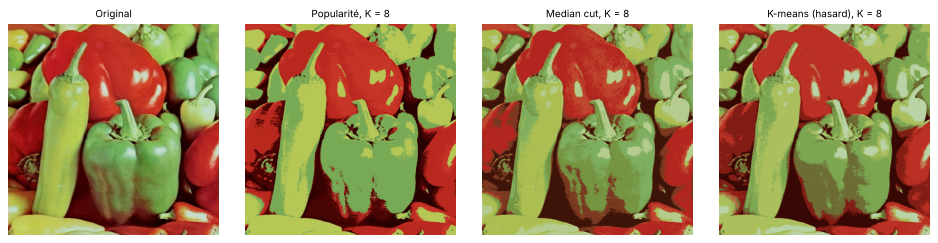

Méthode                         MSE  PSNR (dB)  dE moyen
Popularité                    596.3      20.38     14.39
Median cut                    275.9      23.72     11.61
K-means (hasard)              220.7      24.69     10.34


In [2]:
K = 8
resultats = methodes_classiques(poivrons, K)
afficher_grille([poivrons] + list(resultats.values()), ["Original"] + [f"{n}, K = {K}" for n in resultats], ncol=4, taille=3)
afficher_tableau(poivrons, resultats)

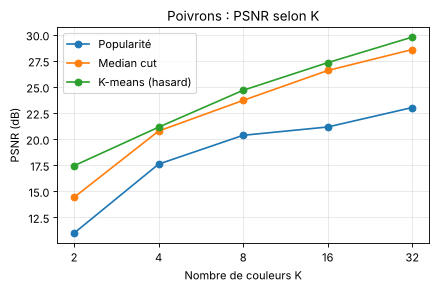

In [3]:
# Erreur en fonction de K (même calcul que comparaison.py, avec moins de valeurs de K)
valeurs_K = [2, 4, 8, 16, 32]
psnr = {}
for K in valeurs_K:
    for nom, q in methodes_classiques(poivrons, K).items():
        psnr.setdefault(nom, []).append(mesures(poivrons, q)[1])
plt.figure(figsize=(6, 3.5))
for nom, v in psnr.items():
    plt.plot(valeurs_K, v, marker="o", label=nom)
plt.xscale("log", base=2)
plt.xticks(valeurs_K, valeurs_K)
plt.xlabel("Nombre de couleurs K")
plt.ylabel("PSNR (dB)")
plt.grid(alpha=0.3)
plt.legend()
plt.title("Poivrons : PSNR selon K")
plt.show()

**Ce qu'on observe.** K-means donne la meilleure erreur, ce qui est logique puisqu'il minimise justement l'erreur quadratique. Le median cut le suit de près, la popularité est nettement moins bonne. Mais aucune de ces courbes ne nous dit **quel $K$ choisir** : le PSNR monte régulièrement, sans « coude » net. On verra au §4.1 que, même avec un bon PSNR, une petite zone de couleur vive peut disparaître complètement. C'est ce qui nous a menés vers la segmentation d'histogrammes.

## 3. La méthode ACoPa

### 3.1 Espace HSI et cylindre des gris

L'article travaille dans l'espace teinte–saturation–intensité (HSI), car la teinte est la composante la plus discriminante pour l'oeil et elle dépend peu de l'éclairage :

$$I=\frac{R+G+B}{3},\qquad S=\sqrt{(R-I)^2+(G-I)^2+(B-I)^2},\qquad H=\arccos\frac{(G-I)-(B-I)}{S\sqrt2}.$$

$S$ est la distance à l'axe des gris et $H$ l'angle autour de cet axe. En codant, on s'est rendu compte que la formule en $\arccos$ ne donne qu'un angle dans $[0^\circ,180^\circ]$. On a donc utilisé $\operatorname{arctan2}$, qui donne le même angle sur tout le cercle (rouge $=0^\circ$, vert $=120^\circ$, bleu $=240^\circ$). L'histogramme de teinte est **circulaire** : $359^\circ$ est voisin de $0^\circ$.

Pour un pixel presque gris, la teinte n'a pas de sens. L'article donne un argument simple : à distance $S$ de l'axe des gris, il y a au plus $2\pi S$ couleurs sur le cercle, donc pour découper la teinte en $Q$ classes il faut $S > \frac{Q}{2\pi}$. Les pixels tels que $S\le\frac{Q}{2\pi}$ forment le **cylindre des gris**. *Exemple :* pour $Q=360$, le seuil vaut $57{,}3$. Le gris $(128,128,128)$ a $S=0$ et est exclu de l'histogramme de teinte, alors que le rouge pur $(255,0,0)$ a $S\approx208$ et y est compté.

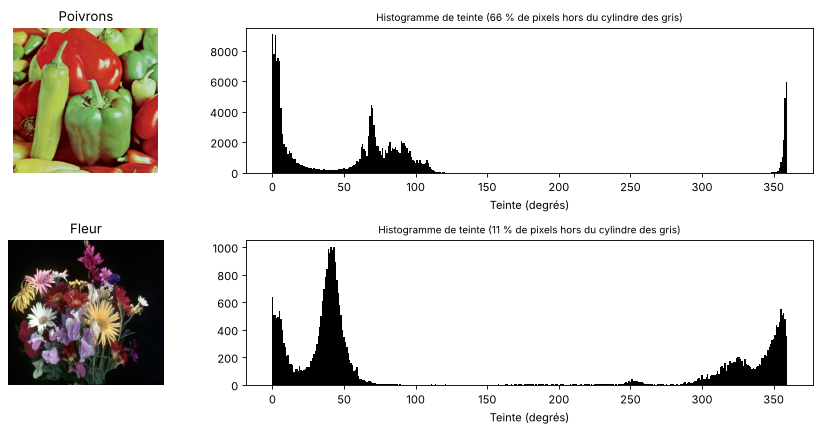

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 5.5), gridspec_kw={"width_ratios": [1, 2.2]})
for ligne, (nom, im) in enumerate([("Poivrons", poivrons), ("Fleur", fleur)]):
    H, S, I = naive.rgb_vers_hsi(im)
    colores = naive.pixels_colores(S)
    h = np.bincount(np.floor(H[colores]).astype(int) % 360, minlength=360)
    axes[ligne, 0].imshow(im)
    axes[ligne, 0].axis("off")
    axes[ligne, 0].set_title(nom)
    axes[ligne, 1].bar(np.arange(360), h, width=1, color="black")
    axes[ligne, 1].set_title(f"Histogramme de teinte ({100 * colores.mean():.0f} % de pixels hors du cylindre des gris)", fontsize=9)
    axes[ligne, 1].set_xlabel("Teinte (degrés)")
plt.tight_layout()
plt.show()

Pour les poivrons, on voit un mode rouge à cheval sur $0^\circ$, ce qui nous a montré que la circularité n'était pas un détail. Viennent ensuite des modes jaune et vert entre $50^\circ$ et $110^\circ$. Pour la fleur, $89\,\%$ des pixels sont dans le cylindre des gris (fond noir). Les teintes rouges et roses, jaunes et violettes forment des modes de tailles très différentes. Le petit mode violet vers $250^\circ$ correspond à quelques petites fleurs : c'est notre équivalent de la « coccinelle » de l'article.

### 3.2 Croissant, décroissant : l'estimateur de Grenander

Pour décider si un morceau d'histogramme $h=(h_1,\dots,h_L)$ est « une seule bosse », on le compare à sa meilleure approximation **décroissante** (ou croissante). C'est l'estimateur de Grenander, que l'on calcule avec l'algorithme **Pool Adjacent Violators** (annexe B de l'article) : tant que deux valeurs successives violent la décroissance, on les remplace par leur moyenne.

*Exemple :* $h=(5,3,4,2)$. Le couple $(3,4)$ viole la décroissance ; on le remplace par $(3{,}5;\,3{,}5)$ et on obtient $(5;\,3{,}5;\,3{,}5;\,2)$, qui est décroissant et a la même masse. C'est d'ailleurs ce cas qu'on a utilisé pour tester notre fonction.

Un morceau est **unimodal** sur $[a,b]$ s'il existe un pic $c$ tel que $h$ est « croissant » sur $[a,c]$ et « décroissant » sur $[c,b]$. Toute la difficulté, qu'on a mis un moment à bien comprendre, est de donner un sens précis à « est croissant » : un histogramme réel n'est jamais exactement monotone à cause du bruit.

### 3.3 Notre première version : un seuil réglé à la main (`segmentation_naive.py`)

Pour commencer simplement, on a mesuré la part des pixels qu'il faut déplacer pour passer de $h$ à son approximation croissante–décroissante $\hat h$ autour du pic $c$ :

$$d(h)=\frac{1}{2N}\sum_{i}\lvert h_i-\hat h_i\rvert,\qquad N=\sum_i h_i,$$

et on a déclaré $h$ unimodal si $d(h)\le\texttt{SEUIL}$. *Exemple :* avec $\texttt{SEUIL}=0{,}05$, un morceau est unimodal s'il suffit de déplacer au plus $5\,\%$ de ses pixels pour le rendre croissant puis décroissant.

On s'est vite aperçus que ce critère ne tient pas compte de $N$. Or un écart de $1\,\%$ sur $200\,000$ pixels ($2\,000$ pixels) ne peut pas être dû au hasard, alors qu'un écart de $1\,\%$ sur $100$ pixels ($1$ pixel) l'est sûrement. La cellule suivante le montre sur un exemple jouet.

Petite bosse : 74 pixels sur 12606
Test                           deux bosses   une bosse bruitée
naïf, SEUIL = 0.05                       1                   1
naïf, SEUIL = 0.01                       1                   1
naïf, SEUIL = 0.003                      2                   1
a contrario, epsilon = 1                 2                   1


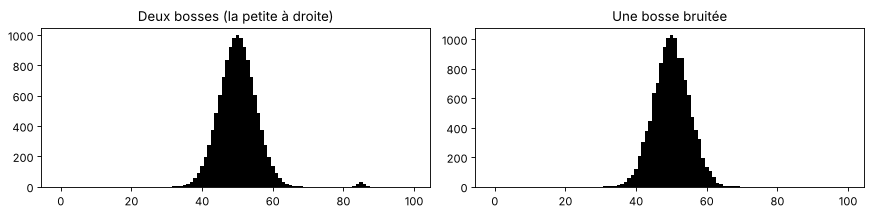

In [5]:
# Une grosse bosse (environ 12 500 pixels) et une petite bosse séparée (74 pixels)
x = np.arange(100)
grosse = np.round(1000 * np.exp(-(x - 50) ** 2 / 50))
petite = np.round(30 * np.exp(-(x - 85) ** 2 / 2))
h = grosse + petite
bruitee = np.random.default_rng(1).poisson(grosse)  # une seule bosse, avec du bruit de comptage

print(f"Petite bosse : {petite.sum():.0f} pixels sur {h.sum():.0f}")
print(f"{'Test':28s}{'deux bosses':>14s}{'une bosse bruitée':>20s}")
for seuil in [0.05, 0.01, 0.003]:
    test = lambda g, s=seuil: naive.est_unimodal_naif(g, s)
    print(f"{'naïf, SEUIL = ' + str(seuil):28s}{len(naive.ftc(h, test)) - 1:>14d}{len(naive.ftc(bruitee, test)) - 1:>20d}")
print(f"{'a contrario, epsilon = 1':28s}{len(naive.ftc(h, auto.est_unimodal_auto)) - 1:>14d}{len(naive.ftc(bruitee, auto.est_unimodal_auto)) - 1:>20d}")

fig, ax = plt.subplots(1, 2, figsize=(11, 2.8))
ax[0].bar(x, h, width=1, color="black"); ax[0].set_title("Deux bosses (la petite à droite)")
ax[1].bar(x, bruitee, width=1, color="black"); ax[1].set_title("Une bosse bruitée")
plt.tight_layout(); plt.show()

Avec notre seuil naïf, il faut descendre à $\texttt{SEUIL}=0{,}003$ pour voir la petite bosse, et ce réglage ne vaut que pour cet histogramme précis. On verra au §4.3 que, sur de vraies images, le nombre de couleurs passe brutalement de quelques centaines à 2 ou 3 quand on change le seuil. Le test a contrario, lui, trouve les deux bosses sans réglage et ne coupe pas la bosse bruitée. C'est ce qui nous a convaincus de l'implémenter.

### 3.4 Version automatique : le test a contrario (`segmentation_auto.py`)

L'article utilise un test multiple introduit par Desolneux, Moisan et Morel et adapté aux histogrammes dans sa référence [10] (Delon et al., IEEE TIP 2007). Voici comment on l'a compris.

Soit $h$ un histogramme de $N$ pixels et $p$ une loi de référence, ici l'estimateur de Grenander normalisé. Pour un intervalle $[a,b]$, on note $r(a,b)$ la proportion observée de pixels dans $[a,b]$ et $p(a,b)$ la proportion attendue. Si $h$ suit vraiment la loi $p$, le nombre de pixels dans $[a,b]$ suit une loi binomiale $\mathcal B(N,p(a,b))$. La probabilité d'un écart au moins aussi grand que celui observé est majorée (borne de Hoeffding) par $e^{-N\,\mathcal H(r,p)}$, avec l'entropie relative

$$\mathcal H(r,p)=r\log\frac rp+(1-r)\log\frac{1-r}{1-p}.$$

Comme on teste **tous** les intervalles, soit $\frac{L(L+1)}{2}$ tests, on définit le **nombre de fausses alarmes**

$$\mathrm{NFA}([a,b])=\frac{L(L+1)}{2}\,e^{-N\,\mathcal H(r(a,b),\,p(a,b))}.$$

On rejette l'hypothèse « $h$ suit $p$ » si un intervalle vérifie $\mathrm{NFA}<\varepsilon$, c'est-à-dire $\mathcal H(r,p)>\frac1N\log\frac{L(L+1)}{2\varepsilon}$. Le seuil **dépend de $N$**, ce qui corrige exactement le défaut de notre première version. Le paramètre $\varepsilon$ a un sens concret : c'est le nombre moyen de fausses détections qu'on accepte sur un histogramme qui suit vraiment $p$. On a pris $\varepsilon=1$, comme dans [10].

*Exemple :* pour un morceau de $L=360$ classes et $N=10\,000$ pixels, on rejette dès que $\mathcal H>\log(64\,980)/10\,000\approx1{,}1\times10^{-3}$. Avec $N=100$ pixels, il faut $\mathcal H>0{,}11$, soit un écart cent fois plus grand.

**Nos simplifications**
- On utilise la borne de Hoeffding plutôt que la queue binomiale exacte. On n'a pas réussi à vérifier dans [10] laquelle des deux formes est utilisée exactement.
- Pour le pic $c$, on essaie seulement les 3 classes les plus hautes du morceau. L'article demande qu'il existe un $c$, ce qui reviendrait à tous les tester, et c'était trop lent en Python.
- On fixe $L=360$ pour tous les histogrammes, par simplicité.

### 3.5 L'algorithme FTC (Fine To Coarse)

1. On part de la segmentation la plus fine : tous les minima locaux de $h$, plus les deux extrémités.
2. On choisit au hasard deux morceaux voisins. Si leur union est unimodale, on les fusionne. On s'arrête quand plus aucune paire ne peut être fusionnée.
3. On recommence avec des unions de $j=3,4,\dots$ morceaux voisins. Petite différence avec l'article : après une fusion à $j\ge3$, on revient à $j=2$, pour être sûrs que la segmentation finale est bien « admissible » au sens de l'article (aucune union de morceaux voisins n'est unimodale).

**Circularité de la teinte.** On coupe le cercle à la classe où l'histogramme est le plus bas, on fait tourner l'histogramme pour qu'elle soit au début, et on applique le FTC classique. C'est une solution qu'on a choisie nous-mêmes : l'article dit seulement que les modes peuvent être circulaires.

### 3.6 Hiérarchie teinte → saturation → intensité

1. On applique le FTC à l'histogramme de teinte des pixels hors du cylindre des gris.
2. On rattache tous les pixels, gris compris, à un mode de teinte selon leur teinte.
3. Pour chaque mode de teinte, on applique le FTC à l'histogramme de saturation de ses pixels.
4. Pour chaque mode (teinte, saturation), on applique le FTC à l'histogramme d'intensité.

Chaque groupe final donne une couleur : la moyenne RGB de ses pixels. Ces couleurs servent de **graines** à K-means (annexe A), en RGB ou en CIE Lab. Le nombre de couleurs $K$ est donc fixé par les données, et non plus par nous.

Fleur : 5 modes de teinte, 9 après la saturation, 17 couleurs au total (0.2 s)


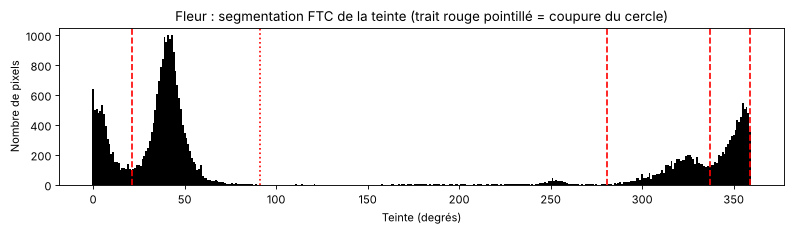

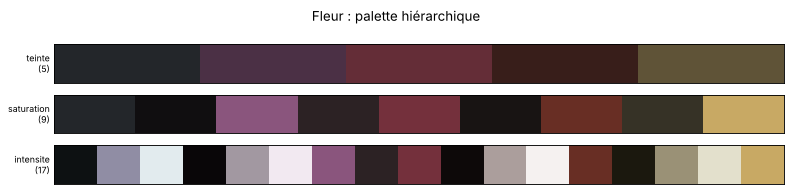

Poivrons : 9 modes de teinte, 20 après la saturation, 39 couleurs au total (0.2 s)


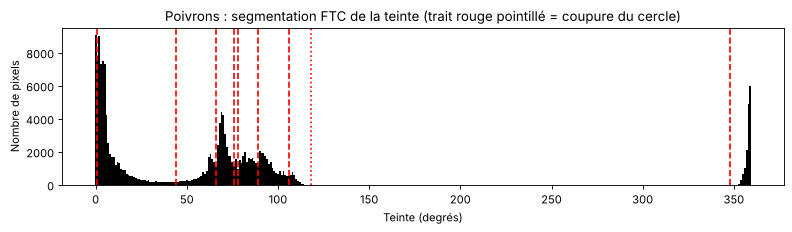

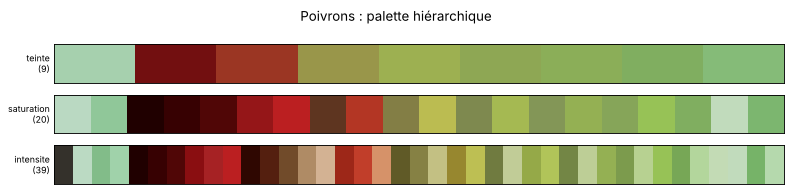

In [6]:
for nom, im in [("Fleur", fleur), ("Poivrons", poivrons)]:
    debut = time.time()
    graines, effectifs, niveaux, infos = naive.palette_acopa(im, auto.est_unimodal_auto, afficher=False)
    print(f"{nom} : {len(niveaux['teinte'])} modes de teinte, {len(niveaux['saturation'])} après la saturation, "
          f"{len(graines)} couleurs au total ({time.time() - debut:.1f} s)")
    naive.afficher_segmentation_teinte(infos["h_teinte"], infos["bornes_H"], infos["decalage"],
                                       f"{nom} : segmentation FTC de la teinte (trait rouge pointillé = coupure du cercle)")
    plt.show()
    naive.afficher_palette_hierarchique(niveaux, f"{nom} : palette hiérarchique")
    plt.show()

Cette palette hiérarchique reproduit la figure 4(e) de l'article : chaque ligne est un niveau de la hiérarchie, et le nombre de couleurs augmente quand on ajoute la saturation puis l'intensité. Pour la fleur, on obtient 5 modes de teinte et 17 couleurs au total. Les violets, roses et jaunes, qui occupent peu de pixels, ont chacun leur couleur.

Pour les poivrons, on obtient 9 modes de teinte, ce qui est plus que ce qu'on voit à l'oeil (rouge, jaune, vert), et 39 couleurs. On revient sur ce point au §5.

Pour vérifier que les modes trouvés ont un sens, on a reproduit la figure 5 de l'article. Pour la fleur, on affiche les pixels qui appartiennent à chaque mode, les autres étant mis en blanc :
- **ligne 1** : les modes de teinte (pixels hors du cylindre des gris) ;
- **ligne 2** : les modes de saturation du plus gros mode de teinte ;
- **ligne 3** : les modes d'intensité du plus gros mode (teinte, saturation).

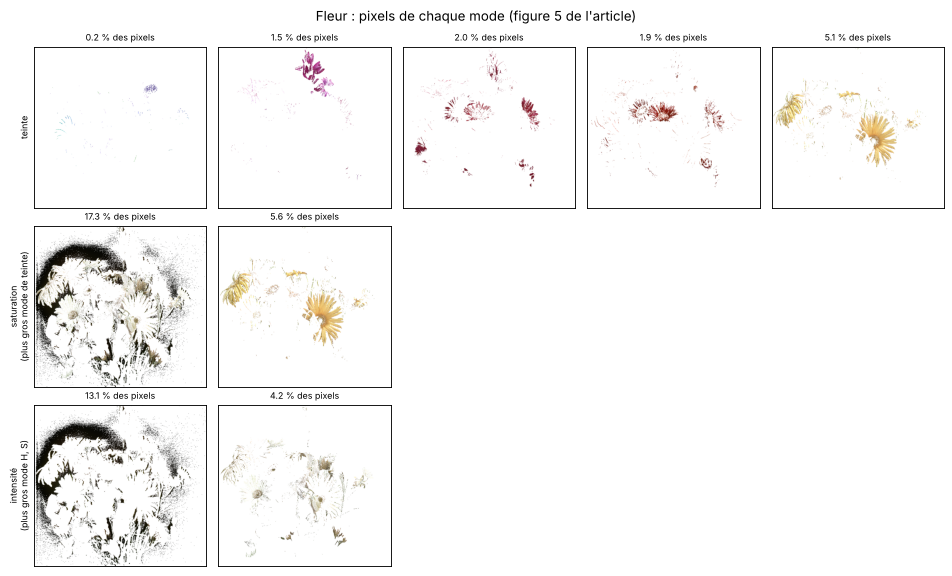

In [7]:
complements.afficher_pixels_des_modes(fleur, "Fleur : pixels de chaque mode (figure 5 de l'article)")
plt.show()

On a été plutôt satisfaits de ce résultat : chaque mode de teinte correspond à un groupe d'objets bien identifiable. On voit les fleurs violettes et bleues (0,2 % des pixels seulement), les fleurs roses, deux groupes de rouges et les fleurs jaunes. Au niveau de la saturation, les pixels gris rattachés au mode jaune (fond sombre, pétales blancs) sont séparés des jaunes saturés. C'est exactement le rôle de l'étape 2 de l'algorithme, qu'on avait du mal à visualiser avant de faire cette figure.

## 4. Expériences

Comme dans l'article, on compare ACoPa + K-means (en RGB et en Lab) aux méthodes classiques **avec le même nombre de couleurs** $K$, celui trouvé par ACoPa. On ajoute aussi Mean-Shift, la quatrième méthode de l'article. Comme Mean-Shift ne prend pas $K$ en paramètre mais une « largeur de bande », on la règle par dichotomie pour obtenir à peu près le même $K$, comme le font les auteurs.

En plus du MSE et du PSNR, on mesure l'écart de couleur $\Delta E$ dans l'espace Lab, en moyenne sur toute l'image et **sur une petite zone de couleur** choisie à l'avance. C'est un ajout de notre part : l'article montre la conservation des petits détails seulement visuellement, et on voulait pouvoir la chiffrer.

### 4.1 Image synthétique « coccinelle »

N'ayant pas l'image de la coccinelle de l'article, on a fabriqué une image test : un fond vert texturé et bruité, avec un petit disque rouge qui occupe $0{,}7\,\%$ de l'image.

ACoPa trouve K = 3 couleurs ; disque rouge = 0.7 % des pixels


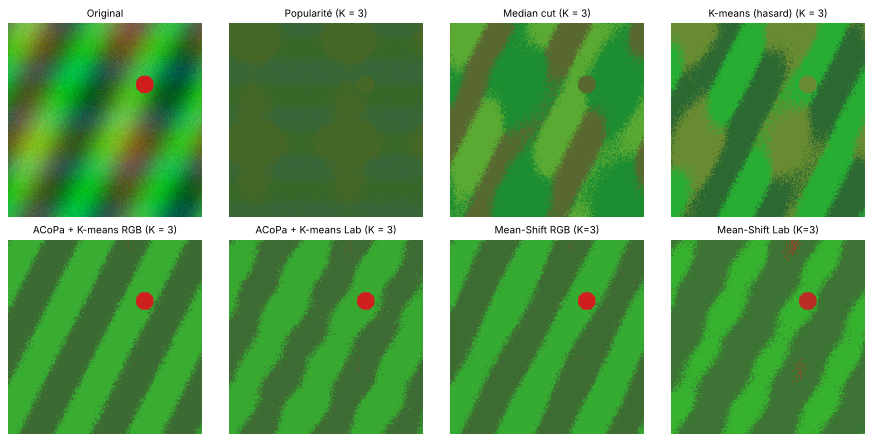

Méthode                         MSE  PSNR (dB)  dE moyen  dE petite zone
Popularité                   1311.2      16.95     29.14           90.67
Median cut                    524.4      20.93     17.56           82.65
K-means (hasard)              500.8      21.13     16.14           93.17
ACoPa + K-means RGB           625.9      20.17     15.47            4.77
ACoPa + K-means Lab           641.3      20.06     15.09            4.77
Mean-Shift RGB (K=3)          629.3      20.14     15.32            4.65
Mean-Shift Lab (K=3)          662.0      19.92     15.82           13.51


In [8]:
rng = np.random.default_rng(0)
y, x = np.mgrid[0:256, 0:256]
fond = np.stack([60 + 40 * np.sin(x / 20) + 30 * np.cos(y / 25),
                 140 + 50 * np.sin(x / 15 + y / 30),
                 50 + 20 * np.cos(y / 10)], axis=-1)
fond += rng.normal(0, 10, fond.shape)
disque = (x - 180) ** 2 + (y - 80) ** 2 < 12 ** 2
fond[disque] = np.array([210, 30, 30]) + rng.normal(0, 8, (disque.sum(), 3))
coccinelle = np.clip(fond, 0, 255).astype(np.uint8)

res_lab, palette, graines, niveaux, infos = auto.acopa_complet(coccinelle, "Lab", afficher=False)
res_rgb, _ = auto.acopa_kmeans(coccinelle, graines, "RGB")
K = len(palette)
resultats = methodes_classiques(coccinelle, K)
resultats["ACoPa + K-means RGB"] = res_rgb
resultats["ACoPa + K-means Lab"] = res_lab
ajouter_mean_shift(resultats, coccinelle, K)
print(f"ACoPa trouve K = {K} couleurs ; disque rouge = {100 * disque.mean():.1f} % des pixels")
afficher_grille([coccinelle] + list(resultats.values()), ["Original"] + [n if "Mean" in n else f"{n} (K = {K})" for n in resultats], ncol=4, taille=2.8)
afficher_tableau(coccinelle, resultats, masque=disque)

Pour nous, c'est le résultat le plus parlant du projet. Avec $K=3$, les trois méthodes classiques dépensent leurs couleurs sur les nuances du fond vert, et le disque rouge disparaît : $\Delta E$ sur le disque entre 80 et 95, c'est-à-dire qu'il devient vert. ACoPa détecte le petit mode rouge dans l'histogramme de teinte et le garde ($\Delta E\approx5$ sur le disque). Mean-Shift garde aussi le disque, surtout en RGB, comme l'observe l'article pour la coccinelle.

En contrepartie, le MSE global d'ACoPa est un peu moins bon que celui de K-means, car une des 3 couleurs est « réservée » à $0{,}7\,\%$ des pixels. On en conclut que le MSE et le PSNR ne mesurent pas ce qu'on cherche ici, d'où l'intérêt de notre mesure sur la petite zone.

### 4.2 Images réelles

Fleur : K = 17 (ACoPa + K-means Lab en 2.3 s), petite zone violette = 524 pixels


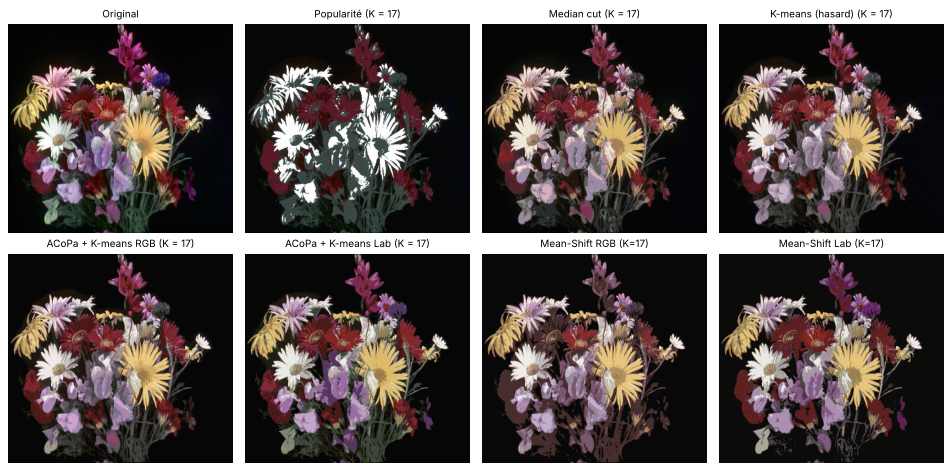

Méthode                         MSE  PSNR (dB)  dE moyen  dE petite zone
Popularité                   1197.2      17.35     12.46           59.22
Median cut                    179.8      25.58      8.45           50.73
K-means (hasard)              131.6      26.94      7.74           47.42


ACoPa + K-means RGB           126.3      27.12      7.50           45.08
ACoPa + K-means Lab           204.9      25.02      6.45           28.11
Mean-Shift RGB (K=17)         232.4      24.47      9.67           29.18
Mean-Shift Lab (K=17)         325.0      23.01      8.41           22.81


Poivrons : K = 39 (ACoPa + K-means Lab en 2.9 s), petite zone violette = 0 pixels


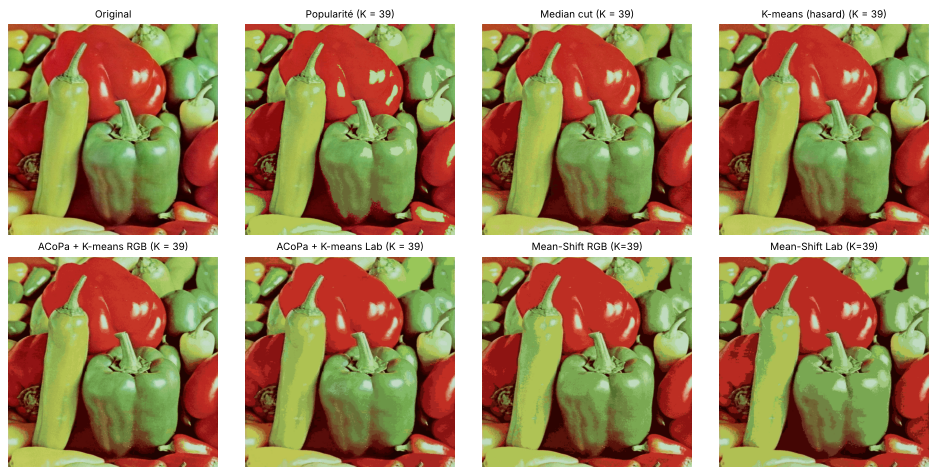

Méthode                         MSE  PSNR (dB)  dE moyen
Popularité                    141.3      26.63      7.68
Median cut                     75.4      29.36      6.57
K-means (hasard)               60.2      30.34      5.92
ACoPa + K-means RGB            60.0      30.35      5.95


ACoPa + K-means Lab           105.2      27.91      5.18
Mean-Shift RGB (K=39)          97.9      28.23      7.06
Mean-Shift Lab (K=39)         164.5      25.97      6.62


In [9]:
for nom, im in [("Fleur", fleur), ("Poivrons", poivrons)]:
    H, S, I = naive.rgb_vers_hsi(im)
    # Petite zone : pixels violets (teinte entre 220 et 280 degrés, hors du cylindre des gris)
    masque = naive.pixels_colores(S) & (H > 220) & (H < 280)
    debut = time.time()
    res_lab, palette, graines, niveaux, infos = auto.acopa_complet(im, "Lab", afficher=False)
    duree = time.time() - debut
    res_rgb, _ = auto.acopa_kmeans(im, graines, "RGB")
    K = len(palette)
    resultats = methodes_classiques(im, K)
    resultats["ACoPa + K-means RGB"] = res_rgb
    resultats["ACoPa + K-means Lab"] = res_lab
    ajouter_mean_shift(resultats, im, K)
    print(f"{nom} : K = {K} (ACoPa + K-means Lab en {duree:.1f} s), petite zone violette = {masque.sum()} pixels")
    afficher_grille([im] + list(resultats.values()), ["Original"] + [n if "Mean" in n else f"{n} (K = {K})" for n in resultats], ncol=4, taille=3)
    afficher_tableau(im, resultats, masque if masque.sum() > 0 else None)

**Fleur ($K=17$).** ACoPa + K-means RGB a la meilleure erreur quadratique, juste devant K-means au hasard. En Lab, le PSNR baisse mais le $\Delta E$ moyen est le meilleur de toutes les méthodes. Surtout, l'erreur sur les fleurs violettes tombe à $\Delta E\approx28$, contre 45 à 60 pour les méthodes classiques. Mean-Shift en Lab fait encore un peu mieux sur cette zone ($\Delta E\approx23$), mais il représente moins bien le reste de l'image ($\Delta E$ moyen de 8,4 contre 6,5, PSNR de 23 dB contre 25 dB). C'est la même conclusion que l'article : seuls Mean-Shift et ACoPa trouvent les petites couleurs, mais **ACoPa + K-means en Lab est le meilleur compromis** entre petits détails et fidélité globale.

**Poivrons ($K=39$).** ACoPa RGB et K-means sont tous les deux autour de 30 dB. Comme il n'y a pas de petite zone de couleur isolée dans cette image, l'avantage d'ACoPa porte surtout sur le choix automatique de $K$. Mean-Shift est ici nettement moins bon. Le résultat en Lab a de nouveau le meilleur $\Delta E$ moyen.

### 4.3 Sensibilité aux paramètres

In [10]:
def nombre_de_couleurs(im, test, **options):
    graines, _, niveaux, _ = naive.palette_acopa(im, test, afficher=False, **options)
    return len(niveaux["teinte"]), len(graines)

print("Version naïve : nombre de couleurs selon SEUIL (teinte / total)")
for seuil in [0.01, 0.02, 0.05, 0.1]:
    test = lambda g, s=seuil: naive.est_unimodal_naif(g, s)
    print(f"  SEUIL = {seuil:<5}  Fleur : {nombre_de_couleurs(fleur, test)}   Poivrons : {nombre_de_couleurs(poivrons, test)}")

print("\nVersion a contrario : nombre de couleurs selon epsilon (teinte / total)")
for eps in [1e-4, 1e-2, 1, 1e2, 1e4]:
    auto.EPSILON = eps
    print(f"  epsilon = {eps:<7g}  Fleur : {nombre_de_couleurs(fleur, auto.est_unimodal_auto)}   Poivrons : {nombre_de_couleurs(poivrons, auto.est_unimodal_auto)}")
auto.EPSILON = 1.0

print("\nVersion a contrario : selon la largeur des classes de S et I (teinte / total)")
for largeur in [1, 2, 4, 6]:
    print(f"  largeur = {largeur}  Fleur : {nombre_de_couleurs(fleur, auto.est_unimodal_auto, largeur=largeur)}   "
          f"Poivrons : {nombre_de_couleurs(poivrons, auto.est_unimodal_auto, largeur=largeur)}")

Version naïve : nombre de couleurs selon SEUIL (teinte / total)


  SEUIL = 0.01   Fleur : (64, 1475)   Poivrons : (10, 74)


  SEUIL = 0.02   Fleur : (56, 657)   Poivrons : (5, 18)


  SEUIL = 0.05   Fleur : (2, 3)   Poivrons : (2, 4)
  SEUIL = 0.1    Fleur : (2, 2)   Poivrons : (2, 2)

Version a contrario : nombre de couleurs selon epsilon (teinte / total)


  epsilon = 0.0001   Fleur : (4, 11)   Poivrons : (8, 35)


  epsilon = 0.01     Fleur : (5, 15)   Poivrons : (8, 37)


... (3 outputs left out)

  largeur = 1  Fleur : (5, 28)   Poivrons : (9, 181)


  largeur = 2  Fleur : (5, 16)   Poivrons : (9, 58)


  largeur = 4  Fleur : (5, 17)   Poivrons : (9, 39)


  largeur = 6  Fleur : (5, 15)   Poivrons : (9, 34)


In [11]:
# Influence de l'ordre aléatoire des fusions dans le FTC (graine du tirage au hasard)
ftc_original = naive.ftc
for nom, im in [("Fleur", fleur), ("Poivrons", poivrons)]:
    nombres = []
    for graine in range(5):
        naive.ftc = lambda h, test, graine_ignoree=0, g=graine: ftc_original(h, test, g)
        nombres.append(len(naive.palette_acopa(im, auto.est_unimodal_auto, afficher=False)[0]))
    naive.ftc = ftc_original
    print(f"{nom} : nombre de couleurs pour 5 ordres de fusion différents : {nombres}")

Fleur : nombre de couleurs pour 5 ordres de fusion différents : [17, 15, 18, 16, 17]


Poivrons : nombre de couleurs pour 5 ordres de fusion différents : [39, 41, 39, 40, 37]


**Ce que nous retenons de ces tableaux**
- **Version naïve :** le nombre de couleurs dépend énormément du seuil. Pour la fleur, il passe de plusieurs centaines (seuil 0,02) à 3 (seuil 0,05). On n'a trouvé aucune valeur qui convienne aux deux images. Comme le seuil est une fraction des pixels, il est trop sévère pour les petits histogrammes et trop laxiste pour les grands.
- **Version a contrario :** quand $\varepsilon$ varie de $10^{-4}$ à $10^{2}$ (six ordres de grandeur), $K$ ne varie que de 11 à 19 pour la fleur et de 35 à 60 pour les poivrons. Comme $\varepsilon$ n'intervient qu'à travers $\log\varepsilon$, il n'y a **pratiquement pas de paramètre à régler**. C'est l'argument principal de l'article, et nos essais le confirment.
- **Largeur des classes de S et I :** avec des classes de largeur 1, les poivrons donnent 181 couleurs, ce qui nous a d'abord surpris. En regardant les histogrammes, on a vu qu'ils sont « en peigne » : les valeurs RGB de cette image sont irrégulièrement remplies (certaines valeurs sont deux fois plus fréquentes que leurs voisines). Le test a contrario, très puissant quand $N$ est grand, voit ces dents comme de vrais modes. On a donc choisi une largeur de 4 par défaut. Ce paramètre n'est pas discuté dans l'article.
- **Ordre des fusions :** le résultat varie de $\pm2$ couleurs selon l'ordre aléatoire des fusions. C'est faible, mais la méthode n'est donc pas totalement déterministe.

### 4.4 Images finales des méthodes automatiques

Pour avoir une vue d'ensemble, on affiche pour chaque photo l'image finale et la palette trouvée (une case par couleur) avec trois méthodes :
- notre version naïve avec le seuil par défaut $\texttt{SEUIL}=0{,}05$ ;
- la version a contrario avec K-means en RGB ;
- la version a contrario avec K-means en Lab.

Aucun $K$ n'est donné à la main. En plus de nos deux images, on a pris trois photos de la bibliothèque `scikit-image` (`astronaut`, `coffee`, `chelsea`), copiées dans `images/`. Le code est dans `demo_resultats.py`, qui enregistre aussi les images dans `resultats/`.

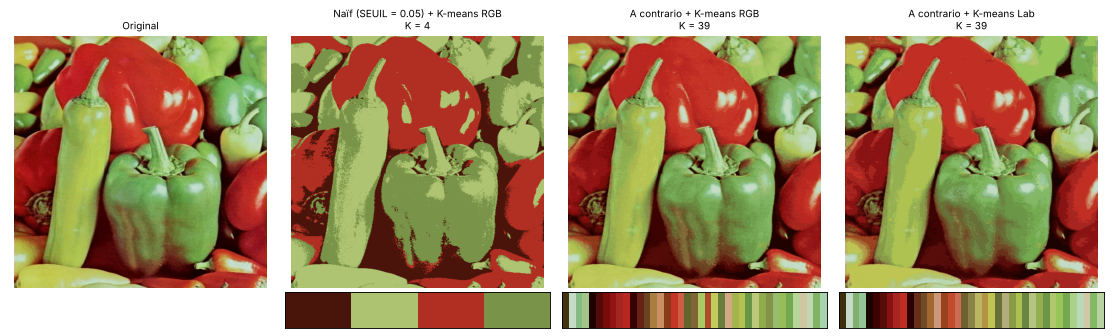

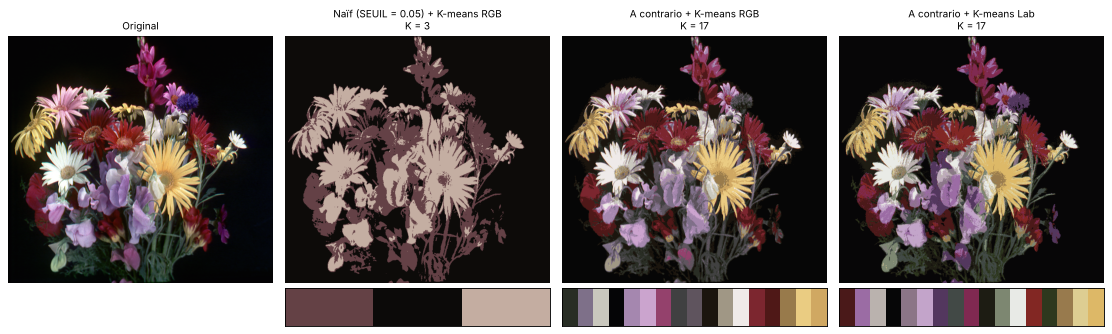

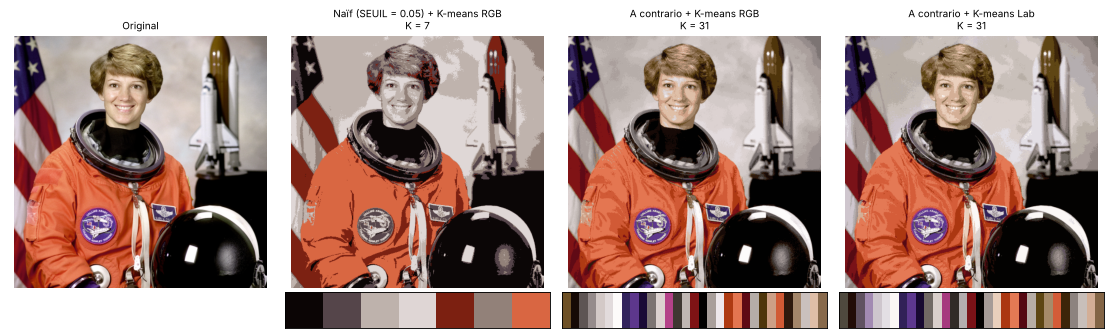

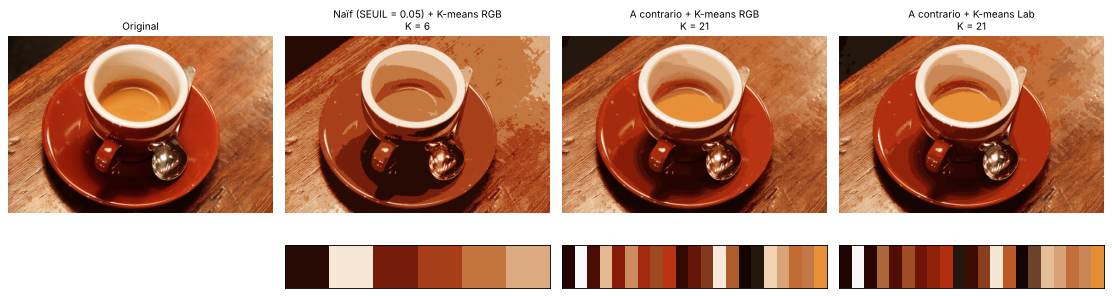

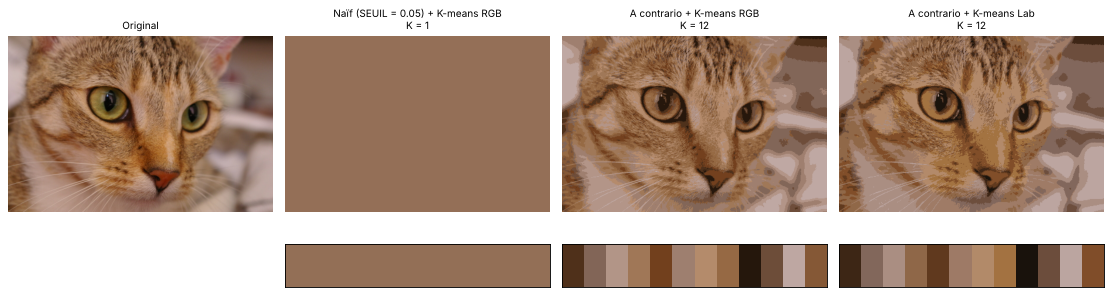

In [12]:
import demo_resultats
for chemin in demo_resultats.IMAGES:
    demo_resultats.afficher_resultats(chemin, enregistrer=False)
    plt.show()

**Nos observations**
- **Version a contrario :** le nombre de couleurs s'adapte au contenu. On obtient $K=12$ pour le chat, dont les couleurs sont peu variées, et jusqu'à $K=39$ pour les poivrons. Les images finales restent très proches des originales.
- **Petits détails :** les détails de couleur vive sont conservés. Par exemple, le bleu du drapeau et l'écusson violet de l'astronaute, ou les fleurs violettes.
- **Version naïve :** le seuil de $5\,\%$ est beaucoup trop permissif pour ces grandes images. Le chat est réduit à une seule couleur ($K=1$), la fleur à 3 couleurs, et le bleu du drapeau disparaît. On retrouve le défaut du §4.3 : le seuil ne tient pas compte du nombre de pixels.
- **RGB ou Lab :** à l'oeil, on voit peu de différence sur ces photos. Elle apparaît surtout dans les mesures du §4.2 (meilleur $\Delta E$ en Lab, meilleur PSNR en RGB).

### 4.5 Nommer les couleurs (section 5 de l'article)

Le but final de l'article est de **décrire** une image avec des noms de couleurs. On a donc donné à chaque couleur de la palette le nom de la couleur la plus proche dans un dictionnaire, au sens de la distance euclidienne dans Lab. Les couleurs qui reçoivent le même nom sont regroupées, et la liste est triée par nombre de pixels.

On a utilisé deux dictionnaires :
- les noms **X11**, dans la version reprise par CSS4 (148 noms, fournis par `matplotlib`). L'article utilise la liste X11 complète de 450 noms, qu'on n'a pas pu récupérer ;
- les **NBS/ISCC Centroids** (267 noms), dans le fichier de J. Jaffer utilisé par les auteurs, qu'on a copié dans `donnees/`.

*Exemple :* une couleur de la palette $(60,\,25,\,30)$, un rouge très sombre, est rattachée dans NBS/ISCC à l'entrée la plus proche dans Lab, du type « darkreddishbrown ».

X11 (CSS4)          : black, darkslategray, gray, darkkhaki, darkslateblue, brown, plum, tan, whitesmoke, thistle, palevioletred, darkgray, palegoldenrod
NBS/ISCC Centroids  : black, oliveblack, darkreddishbrown, darkgrayishgreen, darkolivegreen, moderateyellow, darkpurple, deepred, moderatepurple, grayishpurple, lightbrown, pinkishwhite, lightpurple, deeppurplishred, lightolivegray, pinkishgray, paleyellow


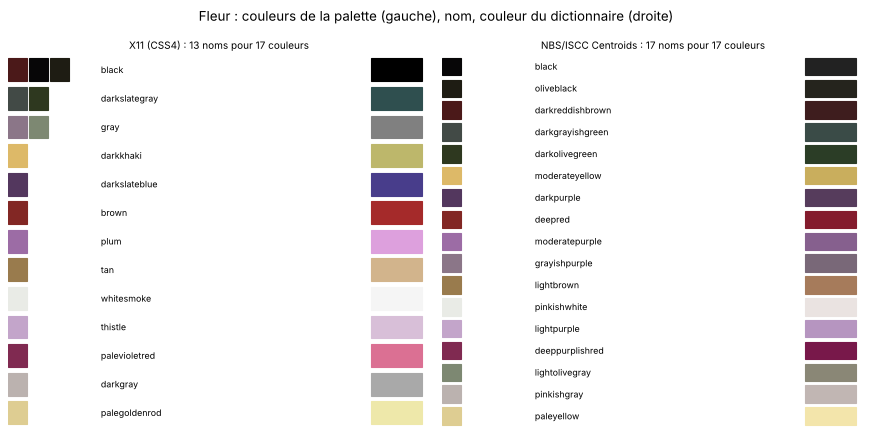

In [13]:
finale, palette, _, _, _ = auto.acopa_complet(fleur, "Lab", afficher=False)
effectifs = complements.effectifs_palette(finale, palette)
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
for ax, (nom_dico, dico) in zip(axes, [("X11 (CSS4)", complements.dictionnaire_x11()),
                                       ("NBS/ISCC Centroids", complements.dictionnaire_nbs())]):
    liste = complements.nommer_palette(palette, effectifs, dico)
    complements.afficher_noms(liste, f"{nom_dico} : {len(liste)} noms pour {len(palette)} couleurs", ax)
    print(f"{nom_dico:20s}: " + ", ".join(nom for nom, _ in liste))
fig.suptitle("Fleur : couleurs de la palette (gauche), nom, couleur du dictionnaire (droite)")
plt.tight_layout()
plt.show()

On retrouve la même observation que l'article. Avec le dictionnaire X11, les 17 couleurs de la palette ne donnent que **13 noms** : plusieurs couleurs sombres différentes (fond, feuillage) sont toutes appelées « black » ou « darkslategray », car X11 a très peu de noms pour les couleurs sombres. Avec NBS/ISCC, on garde **17 noms distincts**, avec des nuances comme « oliveblack » ou « darkreddishbrown ». Comme les auteurs, on trouve NBS/ISCC mieux adapté pour décrire une image, et X11 plus utile si on veut réduire le nombre de couleurs.

## 5. Analyse critique

**Ce qui marche bien, d'après nos essais**
- **$K$ est trouvé automatiquement.** Les valeurs qu'on obtient (12 à 39 selon les photos) sont du même ordre que celles de l'article (« usually less than 30 »).
- **Les petites zones de couleur sont conservées** (§4.1, §4.2, §4.4). C'est l'apport principal par rapport au median cut, à la popularité et à K-means, et on a pu le chiffrer avec le $\Delta E$ sur la zone.
- **Le test a contrario a un seul paramètre, peu sensible**, alors que notre version naïve dépend fortement de son seuil.
- **Le temps de calcul reste raisonnable** : quelques secondes en Python pour une image $512\times512$.

**Limites et difficultés rencontrées**
- **Sensibilité à la quantification et à la compression.** Le test devient très sévère quand $N$ est grand : il détecte toute structure fine des histogrammes, y compris des artefacts. Sur `Poivrons.jpeg`, ça donne trop de modes de teinte (9) et trop de couleurs si on ne regroupe pas les classes de S et I. On en retient qu'un mode « statistiquement significatif » n'est pas toujours une couleur « perceptuellement différente ». Notre choix d'une largeur de 4 est un réglage qui réintroduit un peu d'arbitraire.
- **Graines presque vides.** Certains groupes finaux contiennent moins de 50 pixels et donnent des couleurs presque inutiles. Le nommage du §4.5 réduit déjà un peu $K$, et on pourrait aussi fusionner les couleurs très proches dans Lab après K-means.
- **Erreur quadratique.** ACoPa ne minimise pas l'erreur quadratique. À $K$ égal, son PSNR est comparable à celui de K-means mais pas meilleur, surtout en Lab. Le choix entre RGB et Lab dépend de l'objectif : fidélité moyenne ou couleurs perçues.
- **La hiérarchie H → S → I** fait confiance à la teinte en premier. Deux teintes voisines dans un mode large sont confondues avant même qu'on regarde S et I.

**Écarts avec l'article**
- Borne de Hoeffding au lieu de la queue binomiale exacte, et seulement 3 positions de pic testées (§3.4).
- Coupure du cercle de teinte au minimum de l'histogramme (§3.5).
- Dictionnaire X11 réduit (148 noms au lieu de 450) pour le nommage (§4.5).
- Nous n'avions pas les images de l'article (Ladybug, Olive tree) : l'image synthétique « coccinelle » et les fleurs violettes jouent le même rôle.

**Pistes si on avait plus de temps**
- Utiliser la queue binomiale exacte (`scipy.stats.binom`) et tester tous les pics $c$.
- Fusionner les couleurs de la palette dont le $\Delta E$ est inférieur à un seuil perceptif (par exemple 5).
- Tester sur des images non compressées, pour séparer l'effet de la méthode de celui des artefacts JPEG.

## 6. Utilisation des agents conversationnels

On a utilisé **Claude** (Anthropic), sur claude.ai, tout au long du projet. On détaille ici à quoi il nous a servi, et comment on a vérifié ce qu'il produisait.

**Comprendre l'article.** Claude nous a d'abord traduit l'article en français. On lui a ensuite posé des questions sur les points qu'on ne comprenait pas : l'estimateur de Grenander, l'algorithme Pool Adjacent Violators, la différence entre « unimodal » au sens strict et « unimodal au sens d'un test », le rôle de l'algorithme FTC, et ce que fait le test a contrario de la référence [10]. Par exemple, on lui a demandé si le test d'unimodalité revenait à « détecter une croissance puis une décroissance autour d'un pic ». Il nous a expliqué que c'est bien l'idée, mais que la croissance et la décroissance sont jugées par rapport à l'estimateur de Grenander, et non vérifiées de façon stricte.

**Écrire le code.** Le code de `segmentation_naive.py`, `segmentation_auto.py`, `demo_resultats.py` et `complements.py`, ainsi que le code de ce notebook, a été écrit par Claude à partir de nos demandes, étape par étape. On a d'abord fait HSI et PAV, puis le test à seuil fixé à la main (qu'on avait choisi pour commencer simplement), puis l'affichage des histogrammes et de leur approximation, puis le FTC, le test a contrario, et enfin les compléments (figure 5, Mean-Shift, noms des couleurs). Le median cut (`median_cut.py`) a aussi été écrit avec son aide. Claude a aussi réorganisé le dépôt et corrigé les imports cassés entre nos scripts. Le README précise fichier par fichier qui a écrit quoi.

**Vérifier.** On n'a pas pris le code tel quel :
- tests sur des cas connus : l'exemple $(5,3,4,2)$ de l'annexe B pour PAV, les teintes des couleurs pures pour HSI ;
- histogrammes synthétiques à une et deux bosses (§3.3) ;
- inspection visuelle des histogrammes et des segmentations sur nos images ;
- relecture du code pour pouvoir l'expliquer.

C'est en faisant ces vérifications qu'on a découvert le problème des histogrammes « en peigne » des poivrons (§4.3).

**Rédiger.** Claude nous a aidés à rédiger le compte rendu d'avancement d'octobre et la structure de ce rapport. On a relu et discuté les interprétations des résultats.

**Limites qu'on a rencontrées.** Claude n'a pas pu lire de façon fiable la formule exacte du test dans la référence [10], car le texte du PDF était mal extrait. La forme qu'on utilise (borne de Hoeffding) est donc une reconstruction, et on le signale au §3.4. Plus généralement, l'agent produit du code qui « a l'air juste » : seuls les tests et les figures nous ont permis de vérifier qu'il l'était. On a aussi dû lui demander plusieurs fois un code plus simple, qu'on puisse expliquer à l'oral.

*[À compléter par Hugo : son utilisation des agents conversationnels pour K-means, la popularité et la comparaison.]*

## 7. Répartition du travail et références

| Partie | Qui |
|---|---|
| K-means naïf puis vectorisé, popularité, script de comparaison, première version heuristique d'ACoPa (`acopa_simple.py`) | Hugo |
| Median cut, compte rendu d'avancement, segmentation (versions naïve et automatique), compléments, expériences et rapport | Aziz, avec Claude pour l'écriture du code (voir §6) |

**Références**
1. J. Delon, A. Desolneux, J.-L. Lisani, A.-B. Petro, *Automatic Color Palette*, Inverse Problems and Imaging, 1(2):265-287, 2007.
2. J. Delon, A. Desolneux, J.-L. Lisani, A.-B. Petro, *A nonparametric approach for histogram segmentation*, IEEE Transactions on Image Processing, 16(1):253-261, 2007 (référence [10] de l'article).
3. A. Desolneux, L. Moisan, J.-M. Morel, *From Gestalt Theory to Image Analysis: A Probabilistic Approach*, Springer, 2008.
4. P. Heckbert, *Color image quantization for frame buffer display*, SIGGRAPH, 1982.
5. D. Comaniciu, P. Meer, *Mean shift: a robust approach toward feature space analysis*, IEEE TPAMI, 24(5):603-619, 2002.
6. A. Jaffer, *NBS/ISCC Color System Centroids* (dictionnaire de noms de couleurs, fichier `donnees/NBS-ISCC-rgb.txt`).